# Classification of cross-classification of conflict (full-trial analysis )

## Summary & Notes

### General tasks:
- [x] you can average the you can perform a t test of the before you threshold by p value here.
- [ ] one sample T test against the criteria. she said 50%,
- [ ] get p values for the t values
- [ ] you just have a vector of 128 P values and then and then you can use the FDR algorithm.

### Format classification results (csv) into `main_` dataframe:
- **Variables:**
    - `WS` (type: list): time windows and step size
    - `CRS` and `CRS2` (type: list):  experiment abbreviations; 
        - for cross-context, use `CRS`, for cross-conflict, use `CRS2`
    - `cr_label` (type: dict[list]): labels corresponding to experiment abbreviations (CRS and CRS2)
        - keys: `['US-R', 'UR-S', 'UR-P', 'US-P']`
        - items (type: dict): `['Train', 'Within Test', 'Cross Test', 'Cross Type', 'Within Label', 'Cross Label']`
    - `var_order` (type: dict[list]): ordering of catergorical labels
        - keys: `['Test Classification', 'Train Set', 'Test Set', 'Label']`
    - `main_df` (type: dataframe): results from within and cross context
    - `main2_df` (type: dataframe): results from cross conflict
    - `main_` (type: dataframe): all experimental results combined in one dataframe
    <br>
    <br>

- **Steps:**
    - drop columns: `t_0`, `test_trial_alt_conflict_val`
    - rename columns:
        - `'subject' : 'Subject'`
        - `'classifier' : 'Classifier'`
        - `'window' : 'Trial Length'`
        - `'train_accuracy' : 'Train Accuracy'`
        - `'t_500' : 'Test Accuracy'`
    - add `permutation` column: permutation == np.nan
    - set respective values for:
        - `['Test Classification'] = cr_label[cr]['Cross Type']`
        - `['Train Set'] = cr_label[cr]['Train']`
        - `['Test Set'] = cr_label[cr]['Cross Test']`
        - `['Label'] = cr_label[cr]['Cross Label']`
    - concatenate with previously loaded data frames (`main_df` and `main2_df` -> `main_`)
    - set categorical labels and their order (`var_order`)

## **Part 0:** Set environment: Load packages and set variables

In [1]:
import os, sys
import numpy as np
import itertools, warnings
import pandas as pd


* #### Load stats packages

In [2]:
from scipy import stats
from scipy.stats import ttest_1samp
from statsmodels.stats.multitest import multipletests

* #### Set variables

In [273]:


sys.path.append('/project_data/volume0/tpirnia/data/EEGWS/maybe_repo')
from utils.utils import fill_path
# from stats.fdr import fdr_correction
# from data_handling.preprocessing import get_bad_channels


In [277]:


# w, s = 1000, 500

# Paths:
project_path = "/project_data/volume0/tpirnia/data/EEGWS/"
data_path = "{}results_alias/ch2_aim42/data".format(project_path)
fig_path = "{}results_alias/ch2_aim42/figures".format(project_path)
fill_path(fig_path)

subject_list = "EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33".split(
    " "
)

In [280]:
fill_path(fig_path+'/')

In [208]:
WS, CRS = [[1000, 500], [50, 10]], ["US-R", "UR-S"]
cr_label = {
    "US-R": {
        "Train": "Unrelated vs Semantic",
        "Within Test": "Unrelated vs Semantic",
        "Cross Test": "Unrelated vs Phonological",
        "Cross Type": "Cross Context",
        "Within Label": r"$US \rightarrow S$",
        "Cross Label": r"$US \rightarrow P$",
    },
    "UR-S": {
        "Train": "Unrelated vs Phonological",
        "Within Test": "Unrelated vs Phonological",
        "Cross Test": "Unrelated vs Semantic",
        "Cross Type": "Cross Context",
        "Within Label": r"$UP \rightarrow P$",
        "Cross Label": r"$UP \rightarrow S$",
    },
}

CRS_conflict = ["US-P", "UR-P"]

cr_label = {
    **cr_label,
    "UR-P": {
        "Train": "Unrelated vs Phonological",
        "Within Test": "Unrelated vs Phonological",
        "Cross Test": "Straight vs Reverse Phase",
        "Cross Type": "Cross Conflict",
        "Within Label": r"$UP \rightarrow P$",
        "Cross Label": r"$UP \rightarrow Phase$",
    },
    "US-P": {
        "Train": "Unrelated vs Semantic",
        "Within Test": "Unrelated vs Semantic",
        "Cross Test": "Straight vs Reverse Phase",
        "Cross Type": "Cross Conflict",
        "Within Label": r"$US \rightarrow S$",
        "Cross Label": r"$US \rightarrow Phase$",
    },
}


In [209]:
var_order = {
    "Test Classification": ["Within Context", "Cross Context", "Cross Conflict"],
    "Train Set": ["Unrelated vs Semantic", "Unrelated vs Phonological"],
    "Test Set": [
        "Unrelated vs Semantic",
        "Unrelated vs Phonological",
        "Straight vs Reverse Phase",
    ],
    "Label": [
        r"$US \rightarrow S$",
        r"$UP \rightarrow P$",
        r"$US \rightarrow P$",
        r"$UP \rightarrow S$",
        r"$US \rightarrow Phase$",
        r"$UP \rightarrow Phase$",
    ],
}


## **Part 1:** 1000ms (full trial) analysis

### A. Load Data:
#### (1) Within and Cross Context:

In [725]:
# load within and cross context dataframes
main_df = []
for cr in CRS:
    print("{} \n\t-> {}\n\t-> {}".format(cr_label[cr]["Train"], cr_label[cr]["Within Test"],cr_label[cr]["Cross Test"]))
    out_name = "results_ch2-_context_c_avg.3reps_w{}_s{}-rep3-2_svm_{}_{}".format(
        w, s, cr, "acc"
    )
    cond_fname = (
        project_path + "data/across_subjects/results/" + out_name + "_binary.csv"
    )

    df_ = pd.read_csv(cond_fname)

    within_ind = df_["context_acc"] == "within_condition"
    cross_ind = df_["context_acc"] == "cross_condition"

    df_.drop(columns=["t_0", "test_trial_val"], inplace=True)
    df_["Train Set"] = cr_label[cr]["Train"]

    col_renames = {
        "subject": "Subject",
        "classifier": "Classifier",
        "window": "Trial Length",
        "train_accuracy": "Train Accuracy",
        "t_500": "Test Accuracy",
        "context_acc": "Test Classification",
    }
    df_.rename(columns=col_renames, inplace=True)

    df_["Test Set"] = cr_label[cr]["Within Test"]
    df_.loc[cross_ind, "Test Set"] = cr_label[cr]["Cross Test"]

    df_["Label"] = cr_label[cr]["Within Label"]
    df_.loc[cross_ind, "Label"] = cr_label[cr]["Cross Label"]

    df_.loc[within_ind, "Test Classification"] = "Within Context"
    df_.loc[cross_ind, "Test Classification"] = cr_label[cr]["Cross Type"]

    df_ = df_.drop_duplicates()
    main_df.append(df_)
main_df = pd.concat(main_df)

Unrelated vs Semantic 
	-> Unrelated vs Semantic
	-> Unrelated vs Phonological
Unrelated vs Phonological 
	-> Unrelated vs Phonological
	-> Unrelated vs Semantic


#### (2) Cross Conflict [train: context, test: phase]

In [214]:
# load cross-conflict dataframes
main2_df = []
for cr in CRS_conflict:
    print("{} -> {}".format(cr_label[cr]["Train"], cr_label[cr]["Cross Test"]))
    out_name = "results_ch2-conflict_c_avg.3reps_w{}_s{}-rep3-2_svm_{}_{}".format(
        w, s, cr, "acc"
    )
    cond_fname = project_path + "results_alias/ch2_aim43/" + out_name + "_binary.csv"
    df_ = pd.read_csv(cond_fname)

    df_.drop(columns=["t_0", "test_trial_alt_conflict_val"], inplace=True)

    col_renames = {
        "subject": "Subject",
        "classifier": "Classifier",
        "window": "Trial Length",
        "train_accuracy": "Train Accuracy",
        "t_500": "Test Accuracy",
    }
    df_.rename(columns=col_renames, inplace=True)

    df_["permutation"] = np.nan
    df_["Test Classification"] = cr_label[cr]["Cross Type"]
    df_["Train Set"] = cr_label[cr]["Train"]
    df_["Test Set"] = cr_label[cr]["Cross Test"]
    df_["Label"] = cr_label[cr]["Cross Label"]
    main2_df.append(df_)
    del df_
main2_df = pd.concat(main2_df, ignore_index=True)


Unrelated vs Semantic -> Straight vs Reverse Phase
Unrelated vs Phonological -> Straight vs Reverse Phase


#### (3) Combine cross-analysis experiment [parts 1 and 2]

In [238]:
# combine dataframes & set categorical variable order:
main_ = pd.concat([main_df, main2_df], ignore_index=True)

# set order of categorical variables ('Test Classification', 'Train Set', 'Test Set', 'Label'):
for key in var_order.keys():
    
    _cattype = pd.api.types.CategoricalDtype(categories=var_order[key],
                                            ordered=True)
    main_[key] = main_[key].astype(_cattype)

In [740]:
# set each to explicitely be a dataframe, had some errors otherwise.
main_df = pd.DataFrame(main_df)
main2_df = pd.DataFrame(main2_df)
main_ = pd.DataFrame(main_)

#### (4) Preview data frames:

In [747]:
main_df.loc[(main_df.Subject.eq('EP03'))&( main_df['Train Set'].eq('Unrelated vs Semantic')),:]


,Subject,Classifier,within_condition,cross_condition,Trial Length,step,w_train,permutation,Train Accuracy,Test Accuracy,Test Classification,Train Set,Test Set,Label
0,EP03,svm,2,1,1000,500,1,NaN,0.916667,0.716667,Cross Context,Unrelated vs Semantic,Unrelated vs Phonological,$US \rightarrow P$
1,EP03,svm,2,1,1000,500,1,NaN,0.916667,0.883333,Within Context,Unrelated vs Semantic,Unrelated vs Semantic,$US \rightarrow S$


In [746]:
main2_df.loc[(main2_df.Subject.eq('EP03'))&( main2_df['Train Set'].eq('Unrelated vs Semantic')),:]
# main_[(main_['Subject']=='EP03')&(main_['Train Set']=='Unrelated vs Semantic')]

,Subject,Classifier,within_condition,cross_condition,Trial Length,step,w_train,Train Accuracy,Test Accuracy,permutation,Test Classification,Train Set,Test Set,Label
27,EP03,svm,2,3,1000,500,1,0.933333,0.466667,NaN,Cross Conflict,Unrelated vs Semantic,Straight vs Reverse Phase,$US \rightarrow Phase$


In [748]:
# combined dataframe:
main_.loc[(main_.Subject.eq('EP03'))&( main_['Train Set'].eq('Unrelated vs Semantic')),:]

,Subject,Classifier,within_condition,cross_condition,Trial Length,step,w_train,permutation,Train Accuracy,Test Accuracy,Test Classification,Train Set,Test Set,Label
0,EP03,svm,2,1,1000,500,1,NaN,0.916667,0.716667,Cross Context,Unrelated vs Semantic,Unrelated vs Phonological,$US \rightarrow P$
1,EP03,svm,2,1,1000,500,1,NaN,0.916667,0.883333,Within Context,Unrelated vs Semantic,Unrelated vs Semantic,$US \rightarrow S$
139,EP03,svm,2,3,1000,500,1,NaN,0.933333,0.466667,Cross Conflict,Unrelated vs Semantic,Straight vs Reverse Phase,$US \rightarrow Phase$


#### (5) Save data frames:

In [243]:
# save cross-conflict context:
main_df_out = data_path + '/ch2_crossclassify_conflict-context_1000ms.csv'
main_df.to_csv(main_df_out, index=False)
print('cross-conflict (context) dataframe saved in {}'.format(main_df_out) )

cross-conflict (context) dataframe saved in /project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/data/ch2_crossclassify_conflict-context_1000ms.csv


In [244]:
# save cross-conflict phase:
main2_df_out = data_path + '/ch2_crossclassify_conflict-phase_1000ms.csv'
main2_df.to_csv(main2_df_out, index=False)
print('cross-conflict (phase) dataframe saved in {}'.format(main2_df_out) )

cross-conflict (phase) dataframe saved in /project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/data/ch2_crossclassify_conflict-phase_1000ms.csv


In [245]:
# save all cross-conflict results (without permutations)
main_out = data_path + '/ch2_crossclassify_conflict-all_1000ms.csv'
main_.to_csv(main_out, index=False)
print('cross-conflict (all) dataframe saved in {}'.format(main_out) )

cross-conflict (all) dataframe saved in /project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/data/ch2_crossclassify_conflict-all_1000ms.csv


### **B. Make bar plot figure:**

#### (1) Load Plotting packages and set parameters:

In [193]:
# using matplotlib + seaborn and setting plotting parameters
import matplotlib.pyplot as plt
from mpl_toolkits import axes_grid1
from matplotlib import colors
import matplotlib as mpl
import seaborn as sns

#plot parameters:
plt.rcParams.update(plt.rcParamsDefault)
params = {'lines.markersize':6,
          'axes.labelsize': 20,
          'axes.titlesize':20,
          'axes.labelpad':8,
          'xtick.labelsize' :16,
          'ytick.labelsize' :16,
          'xtick.major.pad':7, 
          'ytick.major.pad':6, 
          'legend.labelspacing':.5,
          'legend.handletextpad':.175,
          'legend.title_fontsize':20,
          'legend.fontsize':20,
          'figure.figsize':(8,10),
          'figure.subplot.hspace': .95,
          'figure.subplot.wspace': .95,
          'image.origin': 'lower',
          'figure.autolayout': False,
          'scatter.marker':'o',
          'savefig.dpi': 450,
          'savefig.bbox': 'tight',
          'savefig.transparent': True,
         }

#### (2) **Plot results:** across context

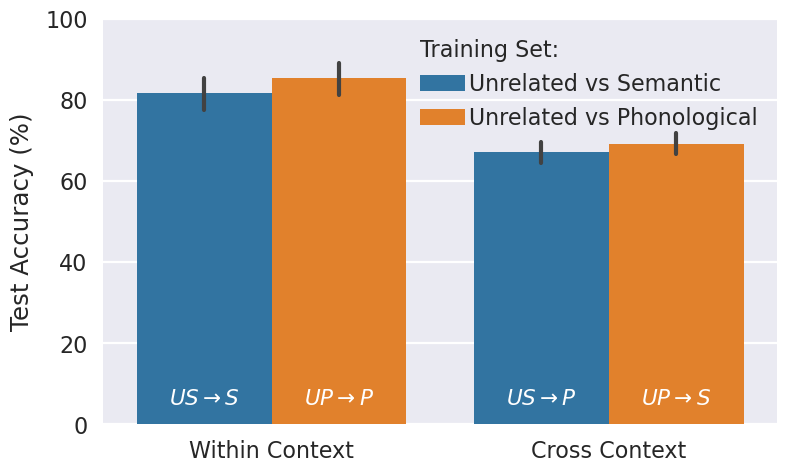

File location:/project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/figures/cross_conflict-context_barplot_1000ms_uncorrected.png


In [749]:
# within and cross context barplot
with mpl.rc_context(params):
    plt.style.use('seaborn-v0_8-darkgrid')
    plt.style.use('seaborn-v0_8-poster')
    # Train and test Accuracy per classifier for full trial length (cue to 1000ms)
    _figdims = (8.7, 5.27)
    _fig, _ax = plt.subplots(figsize=_figdims)
    plt.ylim(0,1)

    _g = sns.barplot(y='Test Accuracy',
                     hue='Train Set',
                     x='Test Classification',
                     order=["Within Context","Cross Context"],
                     data=main_df,
                     ax=_ax, 
                     errwidth=3,
                     errorbar=('ci', 95))
    plt.gca().legend(loc='upper right')
    locs, _ = plt.yticks()
    _ax.xaxis.labelpad = 17
    _ax.set(ylabel='Test Accuracy (%)', 
            yticks=locs, 
            xlabel='',
            yticklabels=list(map(int,locs*100)),)
    ll=var_order["Label"][0:3:2] + var_order["Label"][1:4:2]
    for idx, gg in enumerate(_g.patches):
        _g.text(
            x=(gg.get_x() + (gg.get_width() / 2)),
            y=0.05,
            s=ll[idx],
            ha="center",
            fontsize=15.5,
            color="w",
            fontweight="bold",
        )    
    # plt.gca().legend('', frameon=False) # -nolegend
    # plt.gca().legend(title='Training Set:',title_fontsize=16, bbox_to_anchor=(1.55,1), alignment='left',fontsize=16) # -legend
    plt.gca().legend(title='Training Set:',title_fontsize=16, loc="upper right", alignment='left',fontsize=16)
    fig_fname = (
            fig_path
            + "/cross_conflict-context_barplot_1000ms_uncorrected.png"
        )
    plt.savefig(
        fig_fname,
        dpi=450,
        bbox_inches="tight",
    )
    plt.show()
print(
    "File location:{}".format(fig_fname
    )
)

#### (3) **Plot results:** across conflict

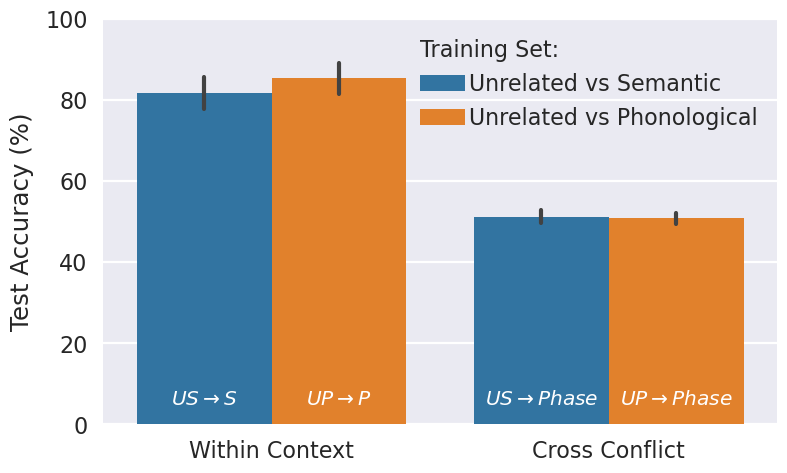

File location:/project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/figures/cross_conflict-phase_barplot_1000ms_uncorrected.png


In [423]:
# cross-conflict barplot 
wc_conflict_tmp = main_[main_['Test Classification'].ne('Cross Context')]
with mpl.rc_context(params):
    plt.style.use('seaborn-v0_8-darkgrid')
    plt.style.use('seaborn-v0_8-poster')
    # Train and test Accuracy per classifier for full trial length (cue to 1000ms)
    _figdims = (8.7, 5.27)
    _fig, _ax = plt.subplots(figsize=_figdims)
    plt.ylim(0,1)

    _g = sns.barplot(y='Test Accuracy',
                     hue='Train Set',
                     x='Test Classification',
                     order=["Within Context","Cross Conflict"],
                     data=wc_conflict_tmp,
                     ax=_ax, 
                     errwidth=3,
                     errorbar=('ci', 95))
    #plt.gca().legend(loc='upper right')
    locs, _ = plt.yticks()
    _ax.xaxis.labelpad = 17
    _ax.set(ylabel='Test Accuracy (%)', 
            yticks=locs, 
            xlabel='',
            yticklabels=list(map(int,locs*100)),)
    ll = var_order["Label"][0::4] + var_order["Label"][1::4]
    for idx, gg in enumerate(_g.patches):
        _g.text(
            x=(gg.get_x() + (gg.get_width() / 2)),
            y=0.05,
            s=ll[idx],
            ha="center",
            fontsize=14.5,
            color="w",
            fontweight="bold",
        )
    # plt.gca().legend('', frameon=False) # -nolegend
    # plt.gca().legend(title='Training Set:',title_fontsize=16, bbox_to_anchor=(1.55,1), alignment='left',fontsize=16) # -legend
    plt.gca().legend(title='Training Set:',title_fontsize=16, loc="upper right", alignment='left',fontsize=16)
    fig_fname = (
            fig_path
            + "/cross_conflict-phase_barplot_1000ms_uncorrected.png"
        )
    plt.savefig(
        fig_fname,
        dpi=450,
        bbox_inches="tight",
    )
    plt.show()
print(
    "File location:{}".format(fig_fname
    )
)


#### (4) **Plot results:** 3-way - cross all conflict
Results in: `/project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/figures/` 

- **`cross_conflict-all_barplot_1000ms_uncorrected.png`**: bar plot with legend in inner upper right corner
- **`cross_conflict-all_barplot_1000ms_uncorrected-nolegend.png`**: bar plot with no legend
- **`cross_conflict-all_barplot_1000ms_uncorrected-legend.png`**: bar plot with legend in outer upper right corner
- **`cross_conflict-all_barplot_1000ms_uncorrected-nolegend-sig.png`**: bar plot with significance marked but NO legend.

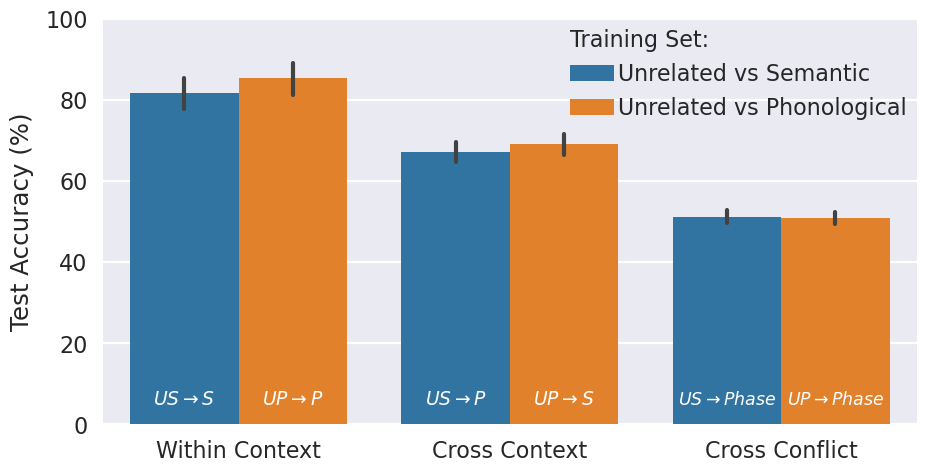

File location:/project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/figures/cross_conflict-all_barplot_1000ms_uncorrected.png


In [750]:
# within context, cross context, and cross context-phase:  bar plot
with mpl.rc_context(params):
    plt.style.use("seaborn-v0_8-darkgrid")
    plt.style.use("seaborn-v0_8-poster")
    # Train and test Accuracy per classifier for full trial length (cue to 1000ms)
    _figdims = (10.5, 5.27)
    _fig, _ax = plt.subplots(figsize=_figdims)
    plt.ylim(0, 1)

    _g = sns.barplot(
        y="Test Accuracy",
        hue="Train Set",
        x="Test Classification",
        data=main_,
        ax=_ax,
        errwidth=3,
        errorbar=("ci", 95),
    )
    #plt.gca().legend(bbox_to_anchor=(1,1))
    locs, _ = plt.yticks()
    _ax.xaxis.labelpad = 17
    _ax.set(
        ylabel="Test Accuracy (%)",
        yticks=locs,
        yticklabels=list(map(int, locs * 100)),
        xlabel="",
    )
    ll = var_order["Label"][0::2] + var_order["Label"][1::2]
    for idx, gg in enumerate(_g.patches):
        _g.text(
            x=(gg.get_x() + (gg.get_width() / 2)),
            y=0.05,
            s=ll[idx],
            ha="center",
            fontsize= 12.5 if idx in [2,5] else 13.5,
            color="w",
            fontweight=800,
        )
    #_fig.gca().legend('', frameon=False) # -nolegend
    #_fig.gca().legend(title='Training Set:',title_fontsize=16, bbox_to_anchor=(1,1), alignment='left',fontsize=16) # -legend
    plt.gca().legend(title='Training Set:',title_fontsize=16, bbox_to_anchor=(.549,1.025), alignment='left',fontsize=16) 
    fig_fname = (
            fig_path
            + "/cross_conflict-all_barplot_1000ms_uncorrected.png"
        )
    plt.savefig(
        fig_fname,
        dpi=450,
        bbox_inches="tight",
    )
    plt.show()
print(
    "File location:{}".format(fig_fname
    )
)


### C. Test Significance
**Variables:**
- **observed results (`OBS`)**: [subject (n=28), experiment (6 total)]<br>
    - type: ndarray, dim: (28,6)
    - values: classification accuracy
    - experiments:
        - within context x 2 (US-S and UP-P)
        - cross context x 2 (US-P and UP-S)
        - cross conflict x 2 (US-phase and UP-phase)
- **experiment names (`OBS_name`)**: abbreviated names for experiments, used for file names
    - type: list, dim: (6,)
    - within context: `US-S` and `UR-R `
    - cross context: `US-R` and `UR-S`
    - cross conflict: `US-P` and `UR-P`
- **experiment labels (`var_order['Label']`)**: abbreviated labels for plotting, uses laTex
    - type: list, dim: (6,)
    - within context: `'$US \\rightarrow S$'` and `'$UP \\rightarrow P$'` 
    - cross context: `'$US \\rightarrow P$'` and `'$UP \\rightarrow S$'`
    - cross conflict:`'$US \\rightarrow Phase$'` and `'$UP \\rightarrow Phase$'`
- **population mean (`pop_mu`)**:  [subject (n=28), experiment (6 total)]
    - type: ndarray, dim: (28,6)
    - value for all is 0.5 as chance accuracy
- **t-test results (`tresults`)**: 
    - type: `scipy.stats._stats_py.Ttest_1sampResult`, tuple:(2,6)

In [685]:
# concatenate test accuracy for each experiment
OBS = []
for i,ll in enumerate(var_order['Label']):
    OBS.append(main_['Test Accuracy'][main_['Label']==ll])
OBS = np.stack(OBS,axis=1)
OBS_name = "US-S UR-R US-R UR-S US-P UR-P".split(" ")

print(var_order['Label'])
print(OBS_name)

['$US \\rightarrow S$', '$UP \\rightarrow P$', '$US \\rightarrow P$', '$UP \\rightarrow S$', '$US \\rightarrow Phase$', '$UP \\rightarrow Phase$']
['US-S', 'UR-R', 'US-R', 'UR-S', 'US-P', 'UR-P']


In [523]:
# set population mean to 50%
pop_mu = np.repeat([[.5,]* OBS.shape[1]],OBS.shape[0],axis=0)


(28, 6)

#### (2) Run one-sample t-test

In [530]:
# Run a 1-sample t-test
tresults = ttest_1samp(OBS, pop_mu[0,:], axis=0, nan_policy='omit',alternative='greater')

tvalues = tresults[0]
pvalues = tresults[1]

#### (3) Correct for multiple comparisons

In [543]:
# Calculate the Benjamini-Hochberg FDR
reject, p_values_corrected, _, _ = multipletests(pvalues, alpha=0.05,method='fdr_bh')

# Print the number of rejected hypotheses and the corrected p-values
print("Number of rejected hypotheses:", np.sum(reject))
print("Corrected p-values:{}".format(p_values_corrected))

Number of rejected hypotheses: 4
Corrected p-values: [8.71869863e-15 4.64984655e-16 9.73852714e-13 7.77320411e-14
 1.17772832e-01 1.45547501e-01]


#### (4) Gather results in a table

In [819]:
from tabulate import tabulate

In [834]:
# print resulting test statistics
print(tabulate({
        "experiment": ["US-S", "UR-R", "US-R", "UR-S", "US-P", "UR-P"],
        "label": var_order["Label"],
        "t-value": tvalues,
        "p-values": pvalues,
        "p-values corrected": p_values_corrected,
        "reject H0": reject,
        "test accuracy (mean)": np.mean(OBS, axis=0),
        "test accuracy (std)": np.std(OBS, axis=0)  }, 
        headers=obs_stats.columns))

experiment    label                     t-value     p-values    p-values corrected    reject H0    test accuracy (mean)    test accuracy (std)
------------  ----------------------  ---------  -----------  --------------------  -----------  ----------------------  ---------------------
US-S          $US \rightarrow S$       15.4991   2.90623e-15           8.7187e-15             1                0.816964              0.106264
UR-R          $UP \rightarrow P$       17.95     7.74974e-17           4.64985e-16            1                0.853869              0.102438
US-R          $US \rightarrow P$       12.3431   6.49235e-13           9.73853e-13            1                0.670238              0.0716663
UR-S          $UP \rightarrow S$       13.9176   3.8866e-14            7.7732e-14             1                0.691071              0.0713367
US-P          $US \rightarrow Phase$    1.32496  0.098144              0.117773               0                0.511905              0.0466873
U

#### (5) Plot cross-conflict (all) bar plot with significance markers

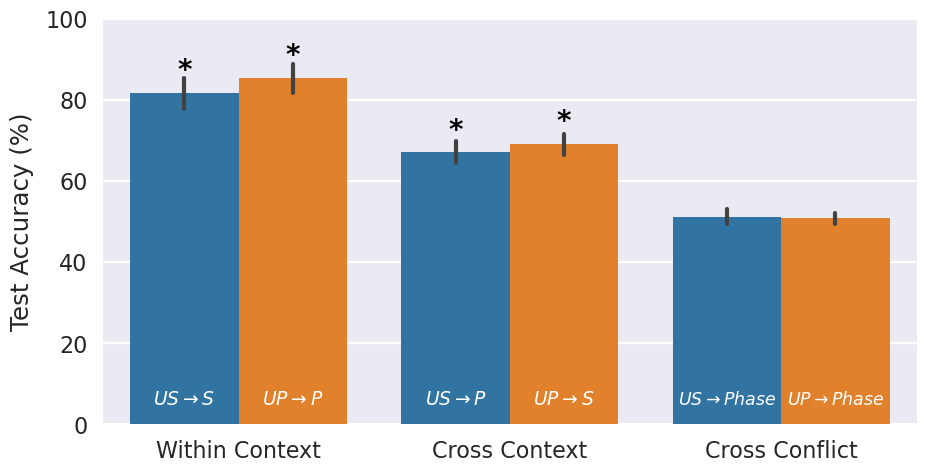

File location:/project_data/volume0/tpirnia/data/EEGWS/results_alias/ch2_aim42/figures/cross_conflict-all_barplot_1000ms_uncorrected-nolegend-sig.png


In [847]:
# within context, cross context, and cross context-phase:  bar plot WITH significance markers and no legend
with mpl.rc_context(params):
    plt.style.use("seaborn-v0_8-darkgrid")
    plt.style.use("seaborn-v0_8-poster")
    # Train and test Accuracy per classifier for full trial length (cue to 1000ms)
    _figdims = (10.5, 5.27)
    _fig, _ax = plt.subplots(figsize=_figdims)
    plt.ylim(0, 1)

    _g = sns.barplot(
        y="Test Accuracy",
        hue="Train Set",
        x="Test Classification",
        data=main_,
        ax=_ax,
        errwidth=3,
        errorbar=("ci", 95),
    )
    #plt.gca().legend(bbox_to_anchor=(1,1))
    locs, _ = plt.yticks()
    _ax.xaxis.labelpad = 17
    _ax.set(
        ylabel="Test Accuracy (%)",
        yticks=locs,
        yticklabels=list(map(int, locs * 100)),
        xlabel="",
    )
    ll = var_order["Label"][0::2] + var_order["Label"][1::2]
    for idx, gg in enumerate(_g.patches):
        _g.text(
            x=(gg.get_x() + (gg.get_width() / 2)),
            y=0.05,
            s=ll[idx],
            ha="center",
            fontsize= 12.5 if idx in [2,5] else 13.5,
            color="w",
            fontweight=800,
        )
        if idx in [0,1,3,4]:
            _g.text(
            x=(gg.get_x() + (gg.get_width() / 2)),
            y=gg.get_height()+.035,
            s="*",
            ha="center",
            fontsize= 20,
            color="black",
            fontweight=800,
        )
    _fig.gca().legend('', frameon=False) # -nolegend
    #_fig.gca().legend(title='Training Set:',title_fontsize=16, bbox_to_anchor=(1,1), alignment='left',fontsize=16) # -legend
    # plt.gca().legend(title='Training Set:',title_fontsize=16, bbox_to_anchor=(.549,1.025), alignment='left',fontsize=16) 
    fig_fname = (
            fig_path
            + "/cross_conflict-all_barplot_1000ms_uncorrected-nolegend-sig.png"
        )
    plt.savefig(
        fig_fname,
        dpi=450,
        bbox_inches="tight",
    )
    plt.show()
print(
    "File location:{}".format(fig_fname
    )
)


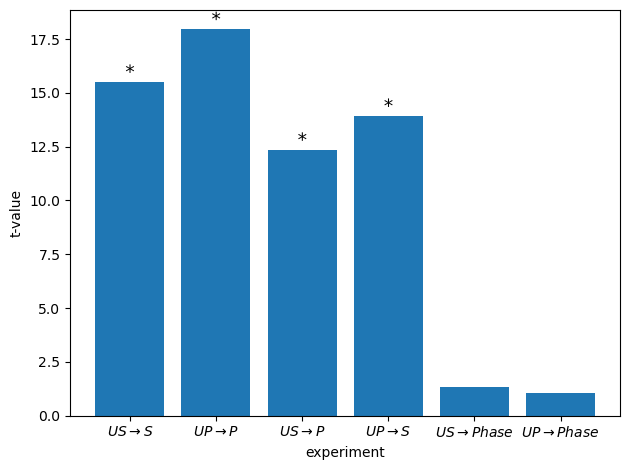

In [848]:
#plot t-statistics
fig,ax = plt.subplots()
reject_labels=np.array(var_order['Label'])[reject]
plt.scatter(np.arange(len(reject_labels)),tvalues[reject]+.5, s=100,  marker="$*$",zorder=2,c='black',edgecolors='none')
plt.bar(x=var_order['Label'], height=tvalues)#, s=65,,marker='s',zorder=1,alpha=.35,c='red',edgecolors='none')
ax.set(ylabel='t-value',xlabel='experiment')#,
y1,y2 = plt.ylim()
ax.xaxis.set_ticks(ticks=np.arange(6),labels=var_order['Label'])
# plt.xlim(-.5,5.5)
# plt.ylim(y1,y2)
# plt.ylim(-0.007,max(pvalues))
# print(plt.ylim())
# plt.ylim(-0.1,max(pvalues))

plt.tight_layout()
plt.show()

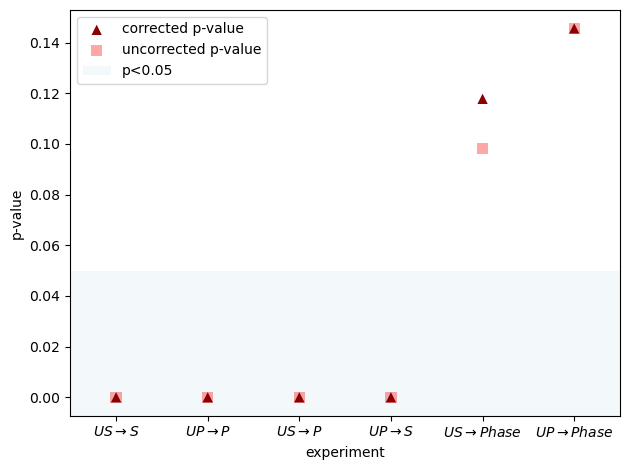

In [ ]:
# visualize p-values before and after fdr correction
fig,ax = plt.subplots()
plt.scatter(np.arange(6), p_values_corrected, s=55, label='corrected p-value', marker='^',zorder=2,c='darkred',edgecolors='none')
plt.scatter(np.arange(6), pvalues, s=65, label='uncorrected p-value',marker='s',zorder=1,alpha=.35,c='red',edgecolors='none')
ax.set(ylabel='p-value',xlabel='experiment')#,
y1,y2 = plt.ylim()
ax.xaxis.set_ticks(ticks=np.arange(6),labels=var_order['Label'])
plt.fill_between(y1=y1,y2=0.05,x=np.arange(-1,7),alpha=.05, label='p<0.05')
plt.xlim(-.5,5.5)
plt.ylim(y1,y2)
# plt.ylim(-0.007,max(pvalues))
# print(plt.ylim())
# plt.ylim(-0.1,max(pvalues))
# y=0.05,label='p=0.05',c='gray', linestyle='--')
plt.legend()
plt.tight_layout()
plt.show()

## **Part 2:** 50ms  sliding window analysis: 
#### see `/maybe_repo/instructions/ch2_crossclassify_conflict_ttest_plot_50ms_draft0.ipynb`*
\* This file hasn't been written yet!

In [2]:
# data/EEGWS/results_alias/ch2_aim42/data/EP03_US-R_Cross_Context_EP03.npy
test_set = ['US-R','UR-S']
test_type = ['Within_Context','Cross_Context']

OBS = []
OBS_name = []
te_type = test_type[1]
for te_set in test_set:
    te_data = []
    te_name = []
    for subject in subject_list:
        # Files saved:
        obs_fname = "{}/{}_{}_{}_{}.npy".format(data_path, subject, te_set, te_type, subject)

        obs_ = np.load(obs_fname)
        te_data.append(obs_)
        te_name.append(te_set)
        print(subject, end=" ")

    OBS.append(te_data)
    OBS_name.append(te_name)


EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33 EP03 EP05 EP06 EP07 EP09 EP10 EP11 EP12 EP13 EP14 EP15 EP16 EP17 EP18 EP19 EP20 EP21 EP22 EP23 EP25 EP26 EP27 EP28 EP29 EP30 EP31 EP32 EP33 

In [5]:
np.stack(OBS).shape

(2, 28, 96, 96)